# Lecture 5 — Class Exercise
## Distribution Charts: Airbnb London

> **Push to:** `week05/lecture05_exercise.ipynb`

**Rules:**
1. Cap price outliers at 95th percentile — annotate this
2. Every chart has a **median/mean reference line** with annotation
3. Insight title names the distribution shape or key finding
4. Colour has meaning — don't use colour just for decoration

---


In [4]:
import pandas as pd
import plotly.express as px
import numpy as np

# Dataset: Airbnb London Listings

df = pd.read_csv('C:\\Users\\nikhi\\DataVisualisation\\data-viz-class-material-w2026\\data\\airbnb_london.csv')
print(f"Loaded: {len(df)} listings")
print(df.describe().round(1))


Loaded: 2500 listings
        price  minimum_nights  number_of_reviews  availability_365  \
count  2500.0          2500.0             2500.0            2500.0   
mean    148.6            14.8              147.9             183.7   
std     110.9             8.4               86.3             105.5   
min      20.5             1.0                0.0               0.0   
25%      71.7             8.0               74.0              92.0   
50%     117.5            15.0              145.0             182.0   
75%     188.9            22.0              222.2             277.0   
max    1032.4            29.0              299.0             364.0   

       reviews_per_month  
count             2500.0  
mean                 2.0  
std                  2.0  
min                  0.0  
25%                  0.6  
50%                  1.4  
75%                  2.8  
max                 15.2  


In [5]:
p95 = df['price'].quantile(0.95)
df_cap = df[df['price'] <= p95]
print(f"95th percentile price: £{p95:.0f}")
print(df_cap.groupby('room_type')['price'].describe().round(1))


95th percentile price: £373
                  count   mean   std   min    25%    50%    75%    max
room_type                                                             
Entire home/apt  1251.0  176.3  75.7  28.0  119.6  163.4  223.5  372.6
Private room      942.0   87.3  39.5  20.9   59.0   78.6  106.0  277.9
Shared room       182.0   46.3  14.1  20.5   36.8   44.1   54.3   92.8


## Task 1 — Histogram: price by room type (overlapping distributions)

**What to build:** A histogram showing price distributions for **Entire home/apt vs Private room** (exclude Shared room — too few observations) overlaid on the same chart.

**Requirements:**
- Both room types on the same chart (use `color='room_type'`)
- `barmode='overlay'` with `opacity=0.6` so both distributions are visible
- A vertical line for the median of EACH room type, differently coloured
- Insight title comparing the two distributions

> 💡 `df_cap[df_cap['room_type'].isin(['Entire home/apt','Private room'])]`


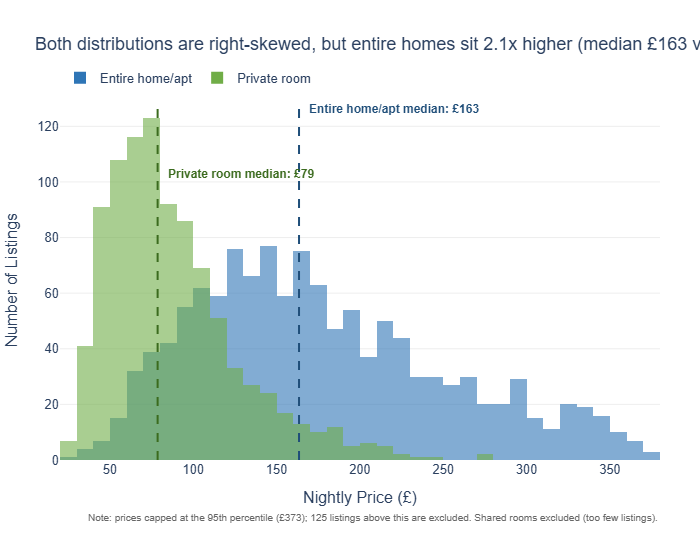

In [6]:
# Task 1 — overlapping price histograms: Entire home/apt vs Private room
df_rt = df_cap[df_cap['room_type'].isin(['Entire home/apt', 'Private room'])].copy()

# Colour = room type (consistent with the lecture box plot): blue = entire home, green = private room
colors = {'Entire home/apt': '#2E75B6', 'Private room': '#70AD47'}
line_colors = {'Entire home/apt': '#1F4E79', 'Private room': '#3B6B1E'}   # darker shades so median lines stand out

medians = df_rt.groupby('room_type')['price'].median()
ratio = medians['Entire home/apt'] / medians['Private room']

fig = px.histogram(
    df_rt, x='price', color='room_type',
    nbins=50,
    barmode='overlay', opacity=0.6,
    color_discrete_map=colors,
    category_orders={'room_type': ['Entire home/apt', 'Private room']},
    labels={'price': 'Nightly Price (£)', 'room_type': 'Room type'},
    height=550
)

# One median line per room type; annotations sit at different heights so they don't collide
for room, ypos, shift in [('Entire home/apt', 1.0, 8), ('Private room', 0.82, 8)]:
    m = medians[room]
    fig.add_vline(x=m, line_dash='dash', line_color=line_colors[room], line_width=2)
    fig.add_annotation(
        x=m, y=ypos, xref='x', yref='paper',
        text=f'<b>{room} median: £{m:.0f}</b>',
        showarrow=False, xanchor='left', xshift=shift,
        font=dict(color=line_colors[room], size=12)
    )

# Disclose the outlier cap
fig.add_annotation(
    x=1, y=-0.18, xref='paper', yref='paper', showarrow=False, xanchor='right',
    text=f'Note: prices capped at the 95th percentile (£{p95:.0f}); {(df["price"] > p95).sum():,} listings above this are excluded. Shared rooms excluded (too few listings).',
    font=dict(size=10, color='#666666')
)

fig.update_layout(
    title=(f'Both distributions are right-skewed, but entire homes sit {ratio:.1f}x higher '
           f'(median £{medians["Entire home/apt"]:.0f} vs £{medians["Private room"]:.0f}) and spread much wider'),
    plot_bgcolor='white', paper_bgcolor='white',
    font=dict(family='Arial', size=13),
    xaxis=dict(showgrid=False, title='Nightly Price (£)'),
    yaxis=dict(gridcolor='#EEEEEE', title='Number of Listings'),
    legend=dict(title='', orientation='h', yanchor='bottom', y=1.02, xanchor='left', x=0),
    margin=dict(l=60, r=40, t=100, b=90)
)
fig.show()
fig.show(renderer="png")

## Task 2 — Box plot: listing activity by borough

**What to build:** A **horizontal box plot** comparing listing activity (reviews per month) across London boroughs — reviews per month is a proxy for how frequently a listing is booked.

**Requirements:**
- Horizontal orientation (borough names are long)
- Sorted by median reviews per month (most active at top)
- Highlight the **two most active** boroughs in a different colour
- Outliers shown as individual points
- Insight title naming the two busiest boroughs

> 💡 Some listings have zero reviews — these are new or inactive listings. Filter them out before plotting

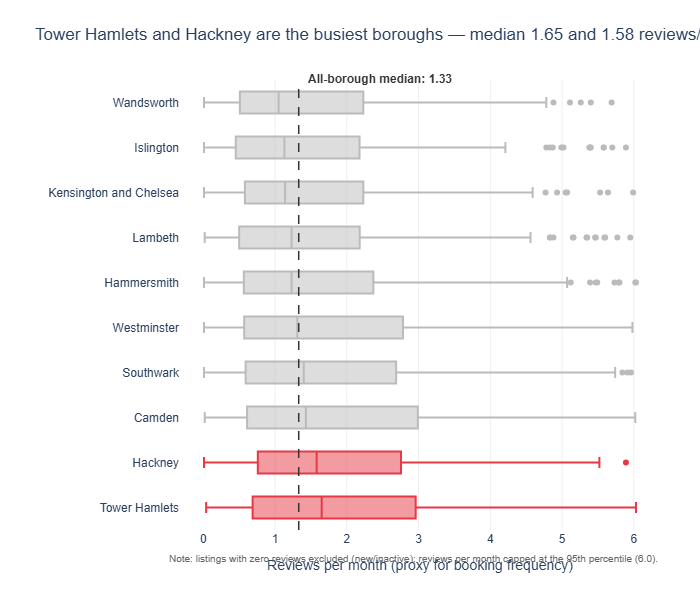

In [7]:
# Task 2 — horizontal box plot: reviews per month by borough
# Zero / missing reviews = new or inactive listings, so filter them out
df_act = df[df['reviews_per_month'] > 0].dropna(subset=['reviews_per_month']).copy()

# Cap the extreme tail here too (same 95th-percentile rule), disclosed in the annotation
rpm_p95 = df_act['reviews_per_month'].quantile(0.95)
df_act = df_act[df_act['reviews_per_month'] <= rpm_p95]

# Sort ascending: in a horizontal plotly box the LAST category is drawn at the TOP -> most active on top
med = df_act.groupby('neighbourhood')['reviews_per_month'].median().sort_values(ascending=True)
order = med.index.tolist()
top2 = med.index[-1], med.index[-2]          # (busiest, second busiest)
overall_median = df_act['reviews_per_month'].median()

# Colour has meaning: highlight = two most active boroughs, everyone else grey
cmap = {b: ('#E63946' if b in top2 else '#BBBBBB') for b in order}

fig = px.box(
    df_act, x='reviews_per_month', y='neighbourhood',
    color='neighbourhood', color_discrete_map=cmap,
    orientation='h',
    points='outliers',                         # outliers as individual points
    category_orders={'neighbourhood': order},
    labels={'reviews_per_month': 'Reviews per month', 'neighbourhood': ''},
    height=max(600, 22 * len(order) + 150)
)

# Overall median reference line
fig.add_vline(x=overall_median, line_dash='dash', line_color='#333333', line_width=1.5)
fig.add_annotation(
    x=overall_median, y=1.0, xref='x', yref='paper', showarrow=False,
    xanchor='left', xshift=6, yshift=10,
    text=f'<b>All-borough median: {overall_median:.2f}</b>',
    font=dict(size=12, color='#333333')
)

# Disclose filters
fig.add_annotation(
    x=1, y=-0.08, xref='paper', yref='paper', showarrow=False, xanchor='right',
    text=(f'Note: listings with zero reviews excluded (new/inactive); reviews per month capped at the '
          f'95th percentile ({rpm_p95:.1f}).'),
    font=dict(size=10, color='#666666')
)

fig.update_layout(
    title=(f'{top2[0]} and {top2[1]} are the busiest boroughs — median {med[top2[0]]:.2f} and '
           f'{med[top2[1]]:.2f} reviews/month vs {overall_median:.2f} overall'),
    plot_bgcolor='white', paper_bgcolor='white',
    font=dict(family='Arial', size=12),
    xaxis=dict(gridcolor='#EEEEEE', title='Reviews per month (proxy for booking frequency)'),
    yaxis=dict(showgrid=False, title=''),
    showlegend=False,
    margin=dict(l=180, r=40, t=80, b=70)
)
fig.show()
fig.show(renderer="png")
